## Correlación Canónica y Análisis Factorial
### Ejemplo y actividad

In [1]:
# Bibliotecas necesarias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_iris, load_breast_cancer, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import FactorAnalysis, PCA
from sklearn.cross_decomposition import CCA
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, r2_score, roc_auc_score

import statsmodels.api as sm
from scipy import stats

sns.set_style('whitegrid')

In [2]:
# ============================================================
# EJEMPLO 1: ANÁLISIS DE CORRELACIÓN CANÓNICA (CCA)
# ============================================================

# Dataset Iris: medimos dos conjuntos de variables
iris = load_iris()
df_iris = pd.DataFrame(iris.data, columns=iris.feature_names)
df_iris.columns = ['Long_Sepalo', 'Ancho_Sepalo', 'Long_Petalo', 'Ancho_Petalo']

# Conjunto X: sépalos. Conjunto Y: pétalos
X_cca = df_iris[['Long_Sepalo', 'Ancho_Sepalo']].values
Y_cca = df_iris[['Long_Petalo', 'Ancho_Petalo']].values

print("Conjunto X (sépalos):", X_cca.shape)
print("Conjunto Y (pétalos):", Y_cca.shape)
print("\nPrimeras filas:")
df_iris.head()

Conjunto X (sépalos): (150, 2)
Conjunto Y (pétalos): (150, 2)

Primeras filas:


,Long_Sepalo,Ancho_Sepalo,Long_Petalo,Ancho_Petalo
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [4]:
# Estandarizar antes de CCA
scaler = StandardScaler()
X_cca_std = scaler.fit_transform(X_cca)
Y_cca_std = scaler.fit_transform(Y_cca)

# Ajustar CCA con 2 componentes
cca = CCA(n_components=2)
U, V = cca.fit_transform(X_cca_std, Y_cca_std)

# Correlaciones canónicas
rho = [np.corrcoef(U[:, i], V[:, i])[0, 1] for i in range(2)]
print("Correlaciones canónicas:")
for i, r in enumerate(rho):
    print(f"  ρ_{i+1} = {r:.4f}  (ρ² = {r**2:.4f})")

Correlaciones canónicas:
  ρ_1 = 0.9410  (ρ² = 0.8854)
  ρ_2 = 0.1239  (ρ² = 0.0154)


In [5]:
# Pesos canónicos (coeficientes)
pesos_X = pd.DataFrame(cca.x_weights_, 
                        index=['Long_Sepalo', 'Ancho_Sepalo'],
                        columns=['U1', 'U2'])
pesos_Y = pd.DataFrame(cca.y_weights_,
                        index=['Long_Petalo', 'Ancho_Petalo'],
                        columns=['V1', 'V2'])

print("Pesos canónicos para X (sépalos):")
print(pesos_X.round(4))
print("\nPesos canónicos para Y (pétalos):")
print(pesos_Y.round(4))

# Cargas canónicas (correlación entre variable original y variable canónica)
cargas_X = pd.DataFrame(
    [np.corrcoef(X_cca_std[:, j], U[:, i])[0, 1] 
     for i in range(2) for j in range(2)],
    index=['U1-Long_Sepalo', 'U1-Ancho_Sepalo', 'U2-Long_Sepalo', 'U2-Ancho_Sepalo'],
    columns=['Carga']
)
print("\nCargas canónicas para X:")
print(cargas_X.round(4))

Pesos canónicos para X (sépalos):
                  U1      U2
Long_Sepalo   0.9217  0.3880
Ancho_Sepalo -0.3880  0.9217

Pesos canónicos para Y (pétalos):
                  V1      V2
Long_Petalo   0.9430  0.3327
Ancho_Petalo -0.3327  0.9430

Cargas canónicas para X:
                  Carga
U1-Long_Sepalo   0.9290
U1-Ancho_Sepalo -0.4767
U2-Long_Sepalo   0.3701
U2-Ancho_Sepalo  0.8791


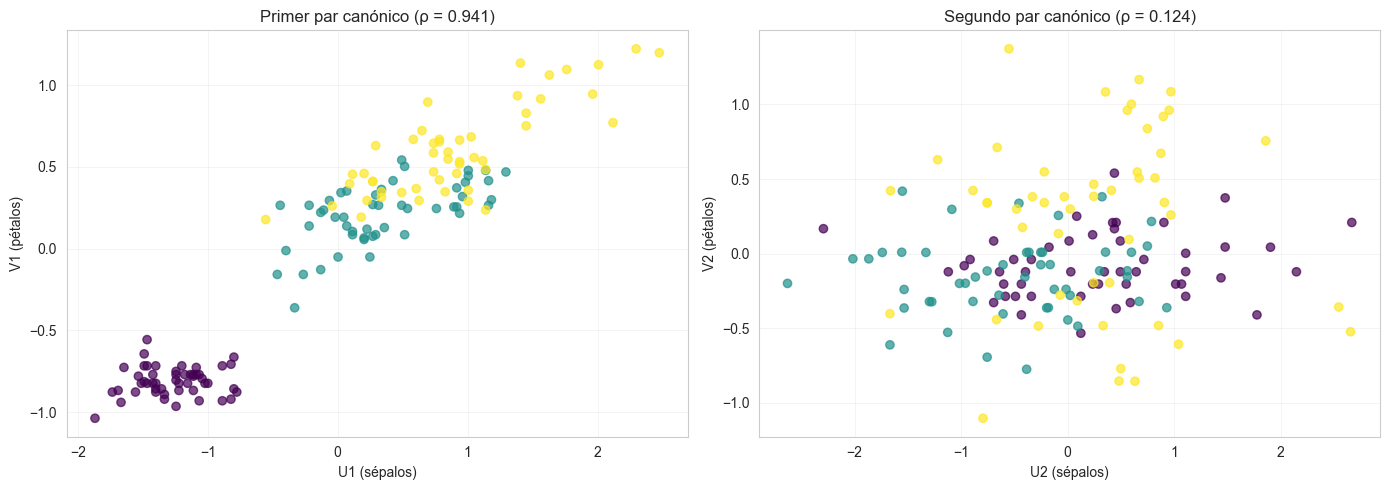

In [6]:
# Scatter de las variables canónicas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Par canónico 1
axes[0].scatter(U[:, 0], V[:, 0], c=iris.target, cmap='viridis', alpha=0.7)
axes[0].set_xlabel('U1 (sépalos)')
axes[0].set_ylabel('V1 (pétalos)')
axes[0].set_title(f'Primer par canónico (ρ = {rho[0]:.3f})')
axes[0].grid(True, alpha=0.3)

# Par canónico 2
axes[1].scatter(U[:, 1], V[:, 1], c=iris.target, cmap='viridis', alpha=0.7)
axes[1].set_xlabel('U2 (sépalos)')
axes[1].set_ylabel('V2 (pétalos)')
axes[1].set_title(f'Segundo par canónico (ρ = {rho[1]:.3f})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
# ============================================================
# PARTE 2: ANÁLISIS FACTORIAL (AF)
# ============================================================

# Dataset Breast Cancer: 30 variables correlacionadas
data_bc = load_breast_cancer()
X_bc = pd.DataFrame(data_bc.data, columns=data_bc.feature_names)
y_bc = data_bc.target

print(f"Forma del dataset: {X_bc.shape}")
print(f"Variables: {X_bc.shape[1]}")
print(f"\nPrimeras variables:")
print(list(X_bc.columns[:10]))

Forma del dataset: (569, 30)
Variables: 30

Primeras variables:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension']


In [8]:
# Seleccionar 10 variables representativas (evitar multicolinealidad extrema)
vars_fa = ['mean radius', 'mean texture', 'mean perimeter', 
           'mean area', 'mean smoothness', 'mean compactness',
           'mean concavity', 'mean concave points',
           'mean symmetry', 'mean fractal dimension']

X_fa = X_bc[vars_fa].values
X_fa_std = StandardScaler().fit_transform(X_fa)

print(f"Variables seleccionadas: {len(vars_fa)}")
print(f"Forma: {X_fa_std.shape}")

Variables seleccionadas: 10
Forma: (569, 10)


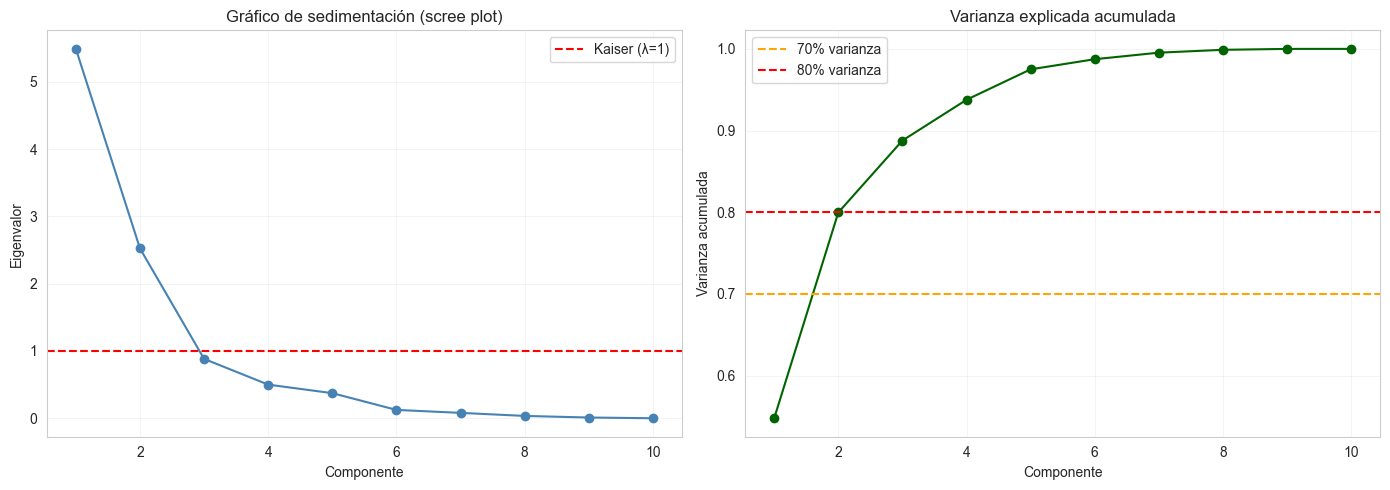


Factores con eigenvalor > 1: 2
Varianza acumulada con 2 factores: 0.800


In [9]:
# Gráfico de sedimentación (scree plot)
pca_temp = PCA()
pca_temp.fit(X_fa_std)
eigenvalues = pca_temp.explained_variance_
varianza_acum = np.cumsum(pca_temp.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(eigenvalues) + 1), eigenvalues, 'o-', color='steelblue')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Eigenvalor')
axes[0].set_title('Gráfico de sedimentación (scree plot)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Varianza acumulada
axes[1].plot(range(1, len(varianza_acum) + 1), varianza_acum, 'o-', color='darkgreen')
axes[1].axhline(y=0.7, color='orange', linestyle='--', label='70% varianza')
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% varianza')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Varianza acumulada')
axes[1].set_title('Varianza explicada acumulada')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Regla de Kaiser
n_factores = sum(eigenvalues > 1)
print(f"\nFactores con eigenvalor > 1: {n_factores}")
print(f"Varianza acumulada con {n_factores} factores: {varianza_acum[n_factores-1]:.3f}")

In [10]:
# Extraer factores con FactorAnalysis (máxima verosimilitud)
fa = FactorAnalysis(n_components=n_factores, random_state=42)
scores_fa = fa.fit_transform(X_fa_std)

# Cargas factoriales
cargas_fa = pd.DataFrame(fa.components_.T,
                          index=vars_fa,
                          columns=[f'F{i+1}' for i in range(n_factores)])

print("Cargas factoriales:")
print(cargas_fa.round(3))

Cargas factoriales:
                           F1     F2
mean radius             0.998 -0.053
mean texture            0.329  0.060
mean perimeter          1.000  0.007
mean area               0.987 -0.044
mean smoothness         0.203  0.679
mean compactness        0.551  0.814
mean concavity          0.712  0.615
mean concave points     0.848  0.458
mean symmetry           0.179  0.619
mean fractal dimension -0.267  0.866


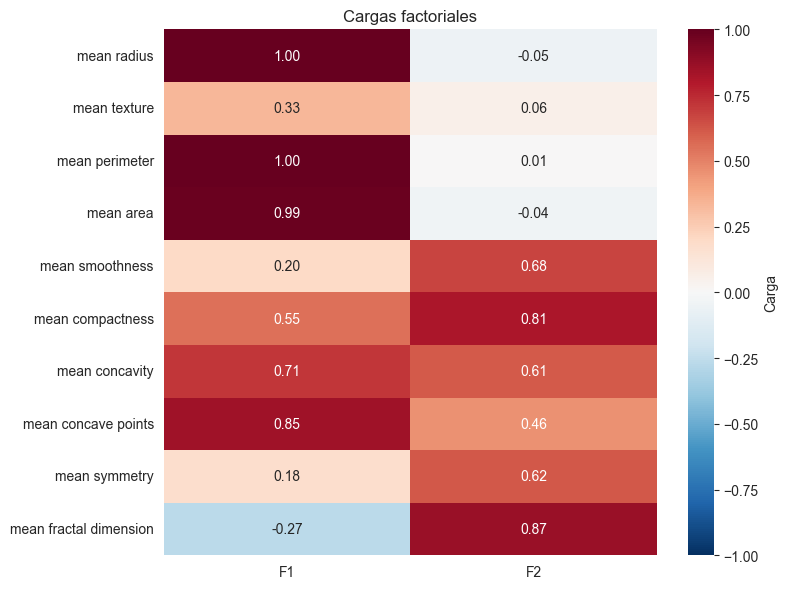


Comunalidades (varianza explicada por factores):
mean radius               0.999
mean texture              0.112
mean perimeter            1.000
mean area                 0.976
mean smoothness           0.502
mean compactness          0.967
mean concavity            0.884
mean concave points       0.929
mean symmetry             0.415
mean fractal dimension    0.821
dtype: float64


In [11]:
# Heatmap de cargas factoriales
plt.figure(figsize=(8, 6))
sns.heatmap(cargas_fa, annot=True, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, fmt='.2f', cbar_kws={'label': 'Carga'})
plt.title('Cargas factoriales')
plt.tight_layout()
plt.show()

# Comunalidades (proporción de varianza explicada por los factores)
comunalidades = (cargas_fa ** 2).sum(axis=1)
print("\nComunalidades (varianza explicada por factores):")
print(comunalidades.round(3))

In [12]:
# ============================================================
# EJEMPLO 3: ANÁLISIS FACTORIAL APLICADO A REGRESIÓN
# ============================================================

# Usamos los scores factoriales como predictores
# Objetivo: clasificar si el tumor es benigno o maligno

# Modelo 1: regresión con variables originales (multicolinealidad)
X_train_orig, X_test_orig, y_train, y_test = train_test_split(
    X_fa_std, y_bc, test_size=0.3, random_state=42, stratify=y_bc
)

modelo_orig = LogisticRegression(max_iter=1000, random_state=42)
modelo_orig.fit(X_train_orig, y_train)
acc_orig = accuracy_score(y_test, modelo_orig.predict(X_test_orig))

# Modelo 2: regresión con scores factoriales
X_train_fa, X_test_fa, _, _ = train_test_split(
    scores_fa, y_bc, test_size=0.3, random_state=42, stratify=y_bc
)

modelo_fa = LogisticRegression(max_iter=1000, random_state=42)
modelo_fa.fit(X_train_fa, y_train)
acc_fa = accuracy_score(y_test, modelo_fa.predict(X_test_fa))

print("=== COMPARACIÓN DE MODELOS ===\n")
print(f"Modelo con variables originales ({X_fa.shape[1]} vars):")
print(f"  Accuracy: {acc_orig:.4f}")
print(f"\nModelo con factores ({n_factores} factores):")
print(f"  Accuracy: {acc_fa:.4f}")
print(f"\nReducción de dimensionalidad: {X_fa.shape[1]} → {n_factores}")

=== COMPARACIÓN DE MODELOS ===

Modelo con variables originales (10 vars):
  Accuracy: 0.9181

Modelo con factores (2 factores):
  Accuracy: 0.9181

Reducción de dimensionalidad: 10 → 2


In [13]:
# ============================================================
# ACTIVIDAD: REPLICAR TODO CON EL DATASET DE VINOS
# ============================================================

print("ACTIVIDAD: Correlación Canónica y Análisis Factorial")
print("=" * 55)
print("\nDataset: Wine (load_wine)")
print("\nInstrucciones:")
print("\n1. CCA:")
print("   - Definir dos conjuntos de variables de vino.")
print("     Ejemplo: X = alcalinidad, magnesio, fenoles totales")
print("              Y = alcohol, ácido málico, ceniza")
print("   - Estandarizar ambos conjuntos")
print("   - Ajustar CCA con 2 componentes")
print("   - Reportar correlaciones canónicas")
print("   - Graficar pares canónicos")
print()
print("2. Análisis Factorial:")
print("   - Seleccionar 8-10 variables del dataset")
print("   - Estandarizar")
print("   - Scree plot para elegir número de factores")
print("   - Extraer factores y reportar cargas")
print("   - Interpretar los factores")
print()
print("3. FA + Regresión:")
print("   - Binificar la variable Clase (ej. 0 vs resto)")
print("   - Ajustar regresión logística con variables originales")
print("   - Ajustar regresión logística con scores factoriales")
print("   - Comparar accuracy de ambos modelos")

ACTIVIDAD: Correlación Canónica y Análisis Factorial

Dataset: Wine (load_wine)

Instrucciones:

1. CCA:
   - Definir dos conjuntos de variables de vino.
     Ejemplo: X = alcalinidad, magnesio, fenoles totales
              Y = alcohol, ácido málico, ceniza
   - Estandarizar ambos conjuntos
   - Ajustar CCA con 2 componentes
   - Reportar correlaciones canónicas
   - Graficar pares canónicos

2. Análisis Factorial:
   - Seleccionar 8-10 variables del dataset
   - Estandarizar
   - Scree plot para elegir número de factores
   - Extraer factores y reportar cargas
   - Interpretar los factores

3. FA + Regresión:
   - Binificar la variable Clase (ej. 0 vs resto)
   - Ajustar regresión logística con variables originales
   - Ajustar regresión logística con scores factoriales
   - Comparar accuracy de ambos modelos


# Actividad: Correlación canónica y análisis factorial del dataset Wine

In [14]:
# Cargamos el dataset
wine = load_wine()
X_wine = pd.DataFrame(wine.data, columns=wine.feature_names)
Y_wine = pd.Series(wine.target, name='Clase')
df_wine = pd.concat([X_wine, Y_wine], axis=1)

print(f'Forma del dataset: {df_wine.shape}')
print(f'Disribución de clases: {df_wine['Clase'].value_counts().sort_index().to_dict()}')
df_wine.head()

Forma del dataset: (178, 14)
Disribución de clases: {0: 59, 1: 71, 2: 48}


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


## Análisis de correlación canónica (CCA)

Definimos los conjuntos de variables:
- X (composición de fenoles y estructurales): alcanilidad de la ceniza, magnesio y los fenoles totales
- Y (características básicas): alcohol, ácido málico y ceniza

Pero nos queda la pregunta, ¿qué combinación lineal de X se relaciona más fuertemente con qué combinación lineal lineal de Y?

In [15]:
# Definir dos conjuntos de variables
vars_X_w = ['alcalinity_of_ash', 'magnesium', 'total_phenols']  # Composición estructulal / fenólica
vars_Y_w = ['alcohol', 'malic_acid', 'ash']                     # Características básicas

X_cca_w = df_wine[vars_X_w].values
Y_cca_w = df_wine[vars_Y_w].values

# Estandarizar (un scaler independiente para cada conjunto)
X_cca_w_std = StandardScaler().fit_transform(X_cca_w)
Y_cca_w_std = StandardScaler().fit_transform(Y_cca_w)

print('Conjunto X:', X_cca_w_std.shape)
print('Conjunto Y:', Y_cca_w_std.shape)

Conjunto X: (178, 3)
Conjunto Y: (178, 3)


In [16]:
# Ajustar CCA con 2 componentes
cca_w = CCA(n_components = 2)
U_w, V_w = cca_w.fit_transform(X_cca_w_std, Y_cca_w_std)

# Correlaciones canónicas
rho_w = [np.corrcoef(U_w[:,i], V_w[:,i])[0,1] for i in range(2)]
print("Correlaciones canónicas:", rho_w)
for i, r in enumerate(rho_w):
    print(f'⍴_{i+1} = {r:.4f} (⍴² = {r**2:.4f})')

Correlaciones canónicas: [np.float64(0.6592210546638508), np.float64(0.5215787029559099)]
⍴_1 = 0.6592 (⍴² = 0.4346)
⍴_2 = 0.5216 (⍴² = 0.2720)


In [19]:
# Pasos canónicos
pesos_X_w = pd.DataFrame(cca_w.x_weights_, index=vars_X_w, columns=['U1', 'U2'])
pesos_Y_w = pd.DataFrame(cca_w.y_weights_, index=vars_Y_w, columns=['V1', 'V2'])
print('Pesos canónicos para X:')
print(pesos_X_w.round(4))
print('\nPesos canónicos para Y:')
print(pesos_Y_w.round(4))

# Cargas canónicas
cargas_X_w = pd.DataFrame(
    [[np.corrcoef(X_cca_w_std[:, j], U_w[:, i])[0, 1] for i in range(2)] for j in range(len(vars_X_w))],
    index=vars_X_w, columns=['U1', 'U2'])
cargas_Y_w = pd.DataFrame(
    [[np.corrcoef(Y_cca_w_std[:, j], V_w[:, i])[0, 1] for i in range(2)] for j in range(len(vars_Y_w))],
    index=vars_Y_w, columns=['V1', 'V2'])
print("\nCargas canónicas para X:")
print(cargas_X_w.round(4))
print("\nCargas canónicas para Y:")
print(cargas_Y_w.round(4))

Pesos canónicos para X:
                       U1      U2
alcalinity_of_ash  0.9880 -0.0834
magnesium          0.1544  0.5278
total_phenols      0.0011  0.8453

Pesos canónicos para Y:
                V1      V2
alcohol    -0.5683  0.5025
malic_acid  0.3243 -0.5910
ash         0.7562  0.6310

Cargas canónicas para X:
                       U1      U2
alcalinity_of_ash  0.9877 -0.1077
magnesium          0.0732  0.6836
total_phenols     -0.2869  0.8378

Cargas canónicas para Y:
                V1      V2
alcohol    -0.4064  0.5988
malic_acid  0.4246 -0.4558
ash         0.7415  0.6454


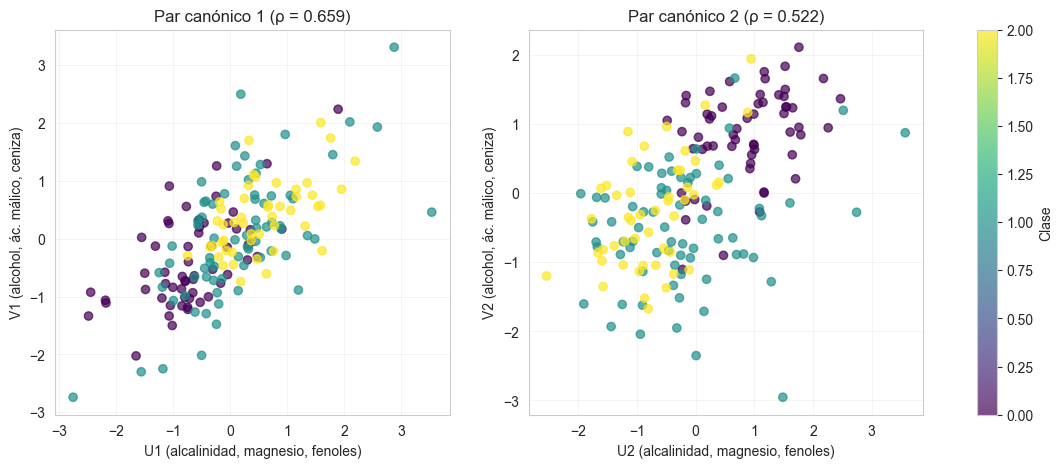

In [20]:
# Scatter de los pares canónicos, coloreado por clase de vino
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for i in range(2):
    sc = axes[i].scatter(U_w[:, i], V_w[:, i], c=df_wine['Clase'], cmap='viridis', alpha=0.7)
    axes[i].set_xlabel(f'U{i+1} (alcalinidad, magnesio, fenoles)')
    axes[i].set_ylabel(f'V{i+1} (alcohol, ác. málico, ceniza)')
    axes[i].set_title(f'Par canónico {i+1} (ρ = {rho_w[i]:.3f})')
    axes[i].grid(True, alpha=0.3)
fig.colorbar(sc, ax=axes, label='Clase')
plt.show()

*Interpretación CCA*
- *Primer par (⍴_1≈0.66, ⍴_2≈0.43):* relación moderada-fuerte; U1 está dominada casi por completo por la alcanilidad de la ceniza y V1 contrasta ceniza y ácido málico contra alcohol; es decir que los vinos con una ceniza más alcalina tienden a tener más ceniza, menos ácido málco y menos alcohol.
- *Segundo par (⍴_1≈0.52, ⍴_2≈0.27):* relación moderada; independiente de la primera; U2 se apoya en fenoles totales y magnesio, V2 contrasta alcohol y ceniza contra ácido málico: vinos con más fenoles y magnesio tienden a tener más alcohol/ceniza y menor concentracón demácido málico.
- A diferencia de Iris (ρ_1 = 0.94), aquí ningún par explica la relación de forma casi total, pues los dos conjuntos comparten información, pero cada uno tiene mucha varianza propia.

# Análisis factorial

Selecionamos 10 variables químicas (excluímos `proline`, `nonflavanoid_phenols` y `od280/od315`, siendo esta última casi que redundante con los flavonoides.

In [21]:
vars_fa_w = ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
             'total_phenols', 'flavanoids', 'proanthocyanins', 'color_intensity', 'hue']

X_fa_w = df_wine[vars_fa_w].values
X_fa_w_std = StandardScaler().fit_transform(X_fa_w)

print(f"Variables seleccionadas: {len(vars_fa_w)}")
print(f"Forma: {X_fa_w_std.shape}")

Variables seleccionadas: 10
Forma: (178, 10)


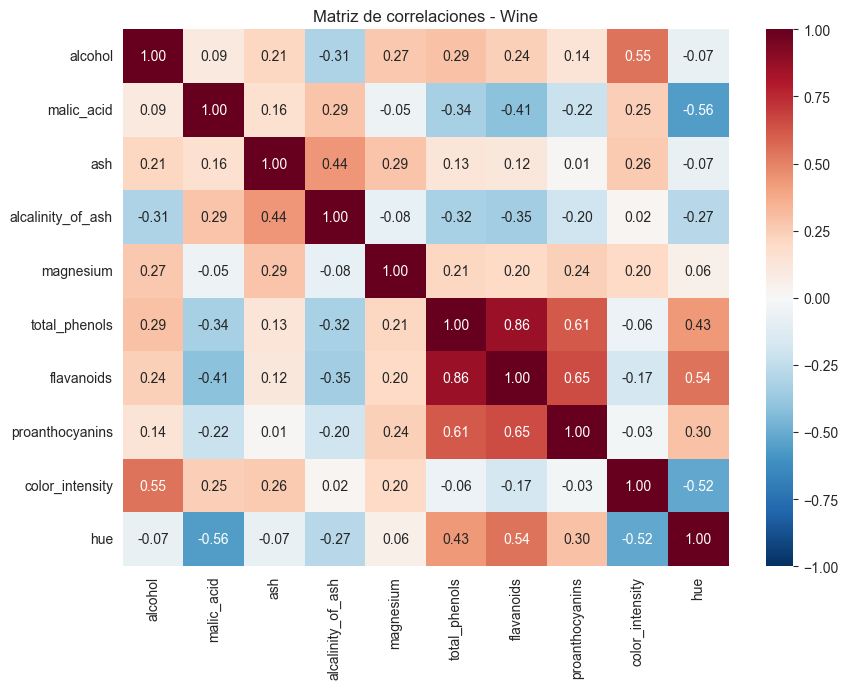

In [23]:
# Matriz de correlaciones
plt.figure(figsize=(9, 7))
sns.heatmap(pd.DataFrame(X_fa_w_std, columns=vars_fa_w).corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Matriz de correlaciones - Wine')
plt.tight_layout()
plt.show()

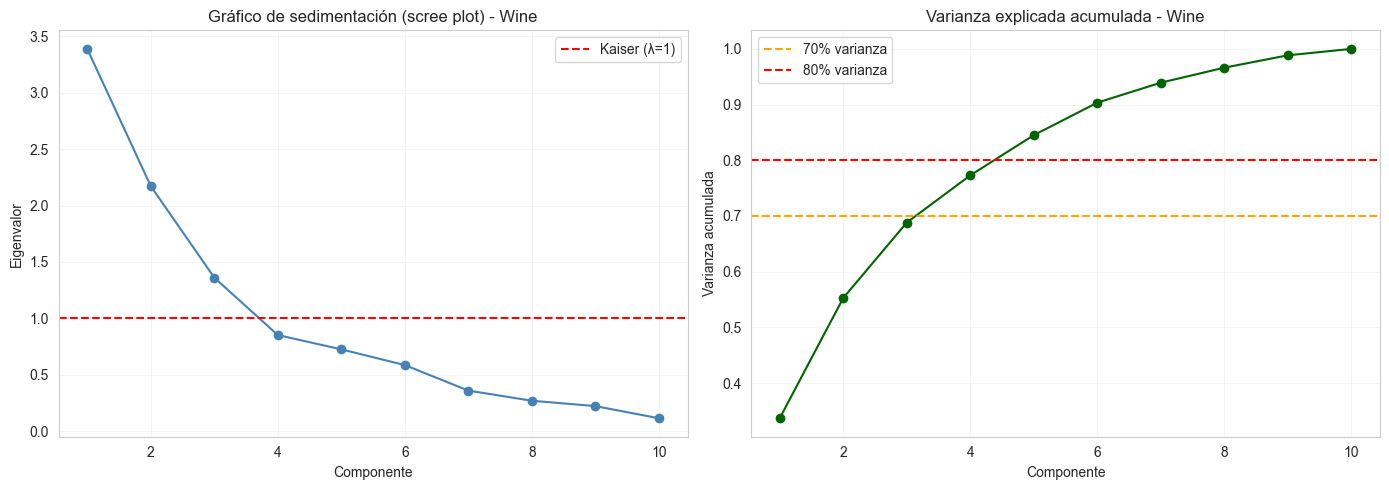

Eigenvalores: [3.387 2.172 1.361 0.853 0.726 0.587 0.361 0.271 0.223 0.116]

Factores con eigenvalor > 1: 3
Varianza acumulada con 3 factores: 0.688


In [24]:
# Scree plot y varianza acumulada
pca_w = PCA().fit(X_fa_w_std)
eigenvalues_w = pca_w.explained_variance_
varianza_acum_w = np.cumsum(pca_w.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(range(1, len(eigenvalues_w) + 1), eigenvalues_w, 'o-', color='steelblue')
axes[0].axhline(y=1, color='r', linestyle='--', label='Kaiser (λ=1)')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Eigenvalor')
axes[0].set_title('Gráfico de sedimentación (scree plot) - Wine')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, len(varianza_acum_w) + 1), varianza_acum_w, 'o-', color='darkgreen')
axes[1].axhline(y=0.7, color='orange', linestyle='--', label='70% varianza')
axes[1].axhline(y=0.8, color='red', linestyle='--', label='80% varianza')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Varianza acumulada')
axes[1].set_title('Varianza explicada acumulada - Wine')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

n_factores_w = sum(eigenvalues_w > 1)
print("Eigenvalores:", eigenvalues_w.round(3))
print(f"\nFactores con eigenvalor > 1: {n_factores_w}")
print(f"Varianza acumulada con {n_factores_w} factores: {varianza_acum_w[n_factores_w-1]:.3f}")

Considearndo en criterio de Kaiser, retenemos 3 factores, los cuales explican *≈70%* de la varianza, siendo que el scree plot también muestra el codo después del tercer componente, mostrando una coincidencia en ambos.

In [25]:
fa_w = FactorAnalysis(n_components=n_factores_w, rotation='varimax', random_state=42)
scores_fa_w = fa_w.fit_transform(X_fa_w_std)

cargas_fa_w = pd.DataFrame(fa_w.components_.T, index=vars_fa_w,
                           columns=[f'F{i+1}' for i in range(n_factores_w)])
print("Cargas factoriales (varimax):")
print(cargas_fa_w.round(3))

Cargas factoriales (varimax):
                      F1     F2     F3
alcohol            0.261 -0.214  0.670
malic_acid        -0.378  0.241  0.299
ash                0.211  0.560  0.311
alcalinity_of_ash -0.247  0.911 -0.066
magnesium          0.236  0.008  0.277
total_phenols      0.886 -0.109  0.059
flavanoids         0.963 -0.128 -0.062
proanthocyanins    0.668 -0.043  0.031
color_intensity   -0.115  0.049  0.869
hue                0.512 -0.197 -0.487


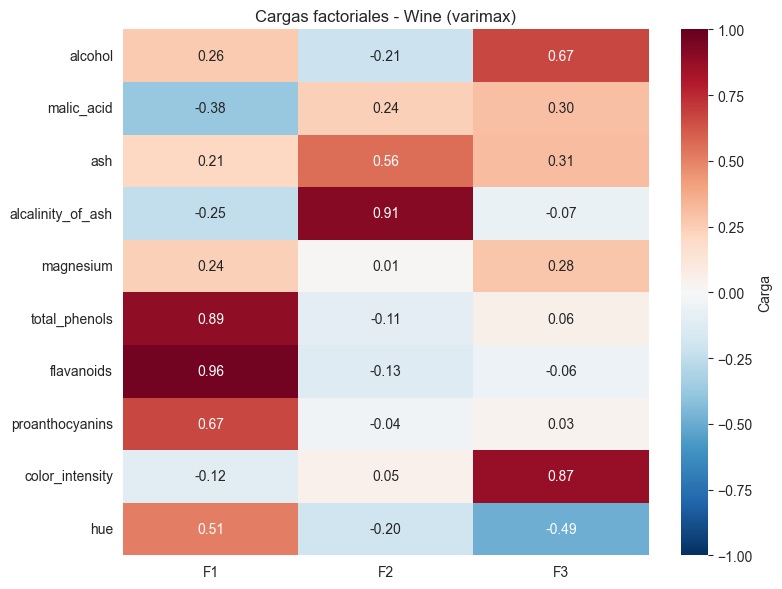

Comunalidades (varianza explicada por los factores):
alcohol              0.563
malic_acid           0.290
ash                  0.455
alcalinity_of_ash    0.895
magnesium            0.133
total_phenols        0.800
flavanoids           0.948
proanthocyanins      0.449
color_intensity      0.770
hue                  0.538
dtype: float64


In [26]:
# Heatmap de cargas factoriales
plt.figure(figsize=(8, 6))
sns.heatmap(cargas_fa_w, annot=True, cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, fmt='.2f', cbar_kws={'label': 'Carga'})
plt.title('Cargas factoriales - Wine (varimax)')
plt.tight_layout()
plt.show()

# Comunalidades
comunalidades_w = (cargas_fa_w ** 2).sum(axis=1)
print("Comunalidades (varianza explicada por los factores):")
print(comunalidades_w.round(3))

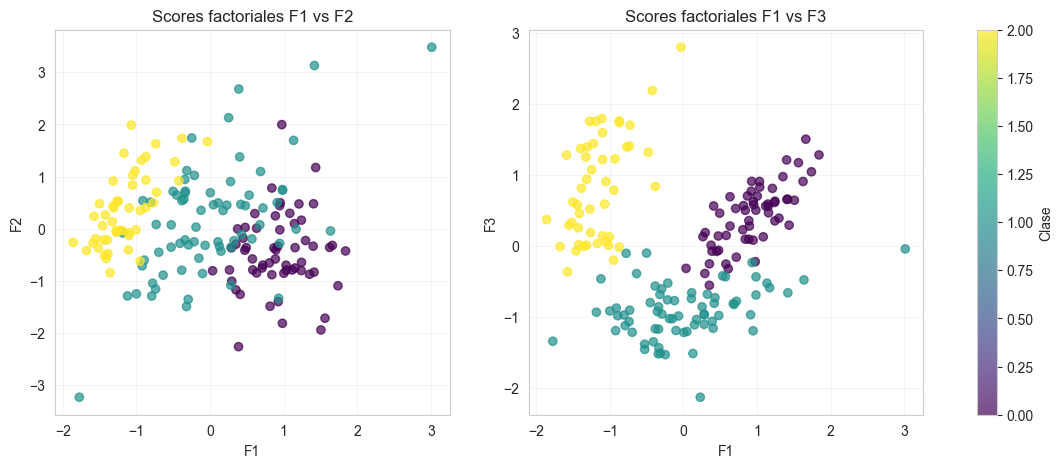

In [27]:
# Scores factoriales coloreados por clase, ¿los factores separan los cultivares?
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (a, b) in zip(axes, [(0, 1), (0, 2)]):
    sc = ax.scatter(scores_fa_w[:, a], scores_fa_w[:, b], c=df_wine['Clase'], cmap='viridis', alpha=0.7)
    ax.set_xlabel(f'F{a+1}')
    ax.set_ylabel(f'F{b+1}')
    ax.set_title(f'Scores factoriales F{a+1} vs F{b+1}')
    ax.grid(True, alpha=0.3)
fig.colorbar(sc, ax=axes, label='Clase')
plt.show()

**Interpretación de los factores:**
- **F1 (Contenido fenólico y estructural):** compuestos responsables del cuerpo y estabilidad del color.
- **F2 (Contenido mineral):** perfil de sales minerales del vino.
- **F3 (Intensidad/Madurez):** vinos más alcohólicos y de color más intenso
-
- Las comunalidades más altas están en flavonoides, fenoles, alcalinidad e intensidad de color.
- **Magnesio** y **ácido málico** tienen comunalidades bajas: buena parte de su varianza es específica y no la comparten con el resto.
- En el scatter F1 vs F3 los tres cultivares se separan bastante bien, lo que anticipa que los factores son buenos predictores de la clase.

## Análisis factorial aplicado a Regresión

volvemos binaria la variable `Clase`: **1 = cultivar 0**, **0 = resto (cultivares 1 y 2)**; comparamos una regresión logística con las 10 variables originales contra una con los 3 scores factoriales. Se usa la misma partición train/test (mismos índices) para ambos modelos.

In [28]:
y_wine_bin = (df_wine['Clase'] == 0).astype(int).values
print(f"Clase 0: {y_wine_bin.sum()} vinos | Resto: {(1 - y_wine_bin).sum()} vinos")

# Una sola partición de índices para que ambos modelos usen exactamente las mismas observaciones
idx_train, idx_test = train_test_split(np.arange(len(y_wine_bin)), test_size=0.3,
                                       random_state=42, stratify=y_wine_bin)
y_train_w, y_test_w = y_wine_bin[idx_train], y_wine_bin[idx_test]

# Modelo 1: variables originales
modelo_orig_w = LogisticRegression(max_iter=1000, random_state=42)
modelo_orig_w.fit(X_fa_w_std[idx_train], y_train_w)
pred_orig_w = modelo_orig_w.predict(X_fa_w_std[idx_test])
acc_orig_w = accuracy_score(y_test_w, pred_orig_w)
auc_orig_w = roc_auc_score(y_test_w, modelo_orig_w.predict_proba(X_fa_w_std[idx_test])[:, 1])

# Modelo 2: scores factoriales
modelo_fa_w = LogisticRegression(max_iter=1000, random_state=42)
modelo_fa_w.fit(scores_fa_w[idx_train], y_train_w)
pred_fa_w = modelo_fa_w.predict(scores_fa_w[idx_test])
acc_fa_w = accuracy_score(y_test_w, pred_fa_w)
auc_fa_w = roc_auc_score(y_test_w, modelo_fa_w.predict_proba(scores_fa_w[idx_test])[:, 1])

print("\n=== COMPARACIÓN DE MODELOS (Wine: clase 0 vs resto) ===\n")
print(f"Modelo con variables originales ({X_fa_w.shape[1]} vars):")
print(f"  Accuracy: {acc_orig_w:.4f} | AUC: {auc_orig_w:.4f}")
print(f"\nModelo con factores ({n_factores_w} factores):")
print(f"  Accuracy: {acc_fa_w:.4f} | AUC: {auc_fa_w:.4f}")
print(f"\nReducción de dimensionalidad: {X_fa_w.shape[1]} → {n_factores_w}")

Clase 0: 59 vinos | Resto: 119 vinos

=== COMPARACIÓN DE MODELOS (Wine: clase 0 vs resto) ===

Modelo con variables originales (10 vars):
  Accuracy: 0.9444 | AUC: 0.9969

Modelo con factores (3 factores):
  Accuracy: 0.8519 | AUC: 0.9660

Reducción de dimensionalidad: 10 → 3


In [29]:
# Coeficientes del modelo con factores: ¿qué factor pesa más para identificar el cultivar 0?
coef_fa_w = pd.Series(modelo_fa_w.coef_[0], index=[f'F{i+1}' for i in range(n_factores_w)])
print("Coeficientes de la regresión logística con factores:")
print(coef_fa_w.round(3))

Coeficientes de la regresión logística con factores:
F1    2.306
F2   -1.078
F3    1.734
dtype: float64


**Lectura de los coeficientes:**
- El cultivar 0 se asocia con un **alto contenido fenólico (F1 > 0)**.
- **Alta intensidad/madurez (F3 > 0)**.
- **Bajo contenido mineral (F2 < 0)**.
El modelo con factores permite describir al cultivar en estos términos, algo que con 10 variables correlacionadas sería mucho más difícil de leer.

La celda siguiente repite el modelo ajustando el escalado y el AF **solo con train** (forma correcta para evitar fuga de información); el resultado es el mismo, así que la comparación anterior es válida.

In [31]:
from sklearn.pipeline import make_pipeline

pipe_fa_w = make_pipeline(StandardScaler(),
                          FactorAnalysis(n_components=n_factores_w, rotation='varimax', random_state=42),
                          LogisticRegression(max_iter=1000, random_state=42))
pipe_fa_w.fit(X_fa_w[idx_train], y_train_w)
print(f"Accuracy AF + regresión (AF ajustado solo en train): "
      f"{accuracy_score(y_test_w, pipe_fa_w.predict(X_fa_w[idx_test])):.4f}")

Accuracy AF + regresión (AF ajustado solo en train): 0.8519


In [32]:
# Paso final :D!
# Celda extra para volver el notebook en un .html

!jupyter nbconvert --to html "Actividad8.ipynb"

[NbConvertApp] Converting notebook Actividad8.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 8 image(s).
[NbConvertApp] Writing 1214008 bytes to Actividad8.html
